# 🤟 Model 1 — MediaPipe landmarks + MLP (ASL)
Chạy lần lượt các cell từ trên xuống. Mỗi bước chỉ **gọi** module trong `src/`, không còn code dài trong notebook.

| Bước | Lệnh |
|---|---|
| Train | `python -m src.models.model1_mlp.train` |
| Đánh giá | `python -m src.models.model1_mlp.evaluate` |
| Demo webcam | `run_webcam_demo()` từ `src.demo.demo_webcam_model1` |

> Dự án đã kèm sẵn `checkpoints/model1_mlp_best.pth` nên có thể **bỏ qua bước Train** và chạy thẳng Evaluate / Demo.

## Cell 1 — Lấy project vào Colab
Upload file `sign-language-recognition.zip` (hoặc đặt nó trong Google Drive).

In [8]:
import os, zipfile
PROJECT = "/content/sign-language-recognition"

if not os.path.exists(PROJECT):
    from google.colab import files
    print("Chọn file zip: sign-language-recognition-colab.zip")
    up = files.upload()
    zname = next(iter(up))
    os.makedirs(PROJECT, exist_ok=True)
    zipfile.ZipFile(zname).extractall(PROJECT)

%cd /content/sign-language-recognition
!ls


/content/sign-language-recognition
checkpoints  data		   notebooks  reports		src
configs      hand_landmarker.task  README.md  requirements.txt	tests


## Cell 2 — Cài thư viện
Colab đã có sẵn torch, sklearn, seaborn, opencv… Chỉ cần `mediapipe` (cho demo).

In [9]:
!pip install -q mediapipe pyyaml

## Cell 3 — Train Model 1 với Data Hybrid mới (61,048 mẫu)
Đọc dữ liệu từ `data/hybrid_manifest/{train,val,test}.csv` + `configs/config.yaml`.
Tự động áp dụng Data Augmentation (lật gương nhân đôi dữ liệu hai tay + xoay/co giãn/nhiễu on-the-fly).


In [10]:
!python -m src.models.model1_mlp.train

PyTorch: 2.11.0+cu130 | Thiết bị: cuda
Kích thước ban đầu train / val: (41788, 63), (8955, 63)
Số lớp: 28 -> ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'space']
⚡ Đang áp dụng augmentation: Lật gương tập train (x2 dữ liệu để học cả hai tay)...
👉 Kích thước train sau khi nối đôi: (83576, 63) (nhãn giữ nguyên)
👉 Kích thước val sau khi gộp hai tay: (17910, 63)
LandmarkMLP(
  (net): Sequential(
    (0): Linear(in_features=63, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, mome

## Cell 4 — Đánh giá trên tập test
In Accuracy + classification report, lưu confusion matrix vào `reports/confusion_matrices/`.

🎯 KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (3 CON SỐ TÁCH BIỆT):
  (a) Test gốc (tay phải):          98.86%
  (b) Test lật gương (mô phỏng tay trái): 98.87%
  (c) Gộp cả hai (hai tay):         98.87%

📊 Báo cáo phân loại chi tiết (Tập test gộp hai tay):
              precision    recall  f1-score   support

           A      0.997     0.994     0.995       626
           B      0.997     0.997     0.997       644
           C      0.987     1.000     0.993       528
           D      0.993     0.988     0.991       688
           E      1.000     0.991     0.995       660
           F      0.996     1.000     0.998       826
           G      1.000     1.000     1.000       686
           H      0.997     0.996     0.996       686
           I      0.988     0.987     0.987       680
           J      0.997     0.993     0.995       728
           K      0.992     0.990     0.991       778
           L      0.999     0.997     0.998       724
           M      0.880     0.961     0.919       358

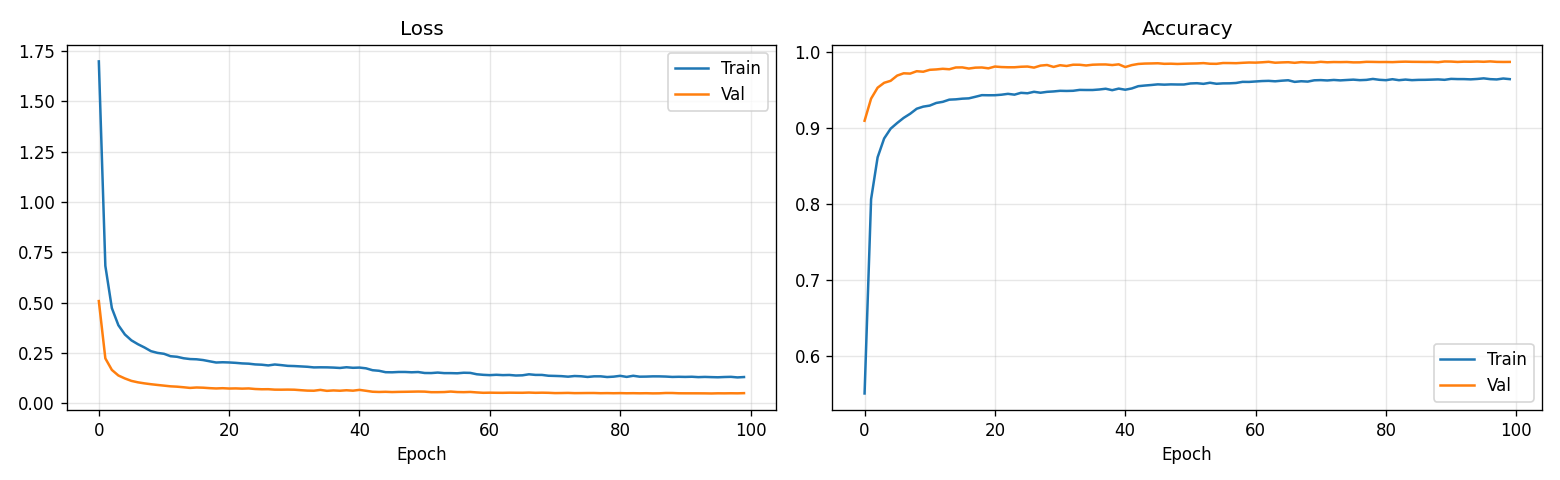

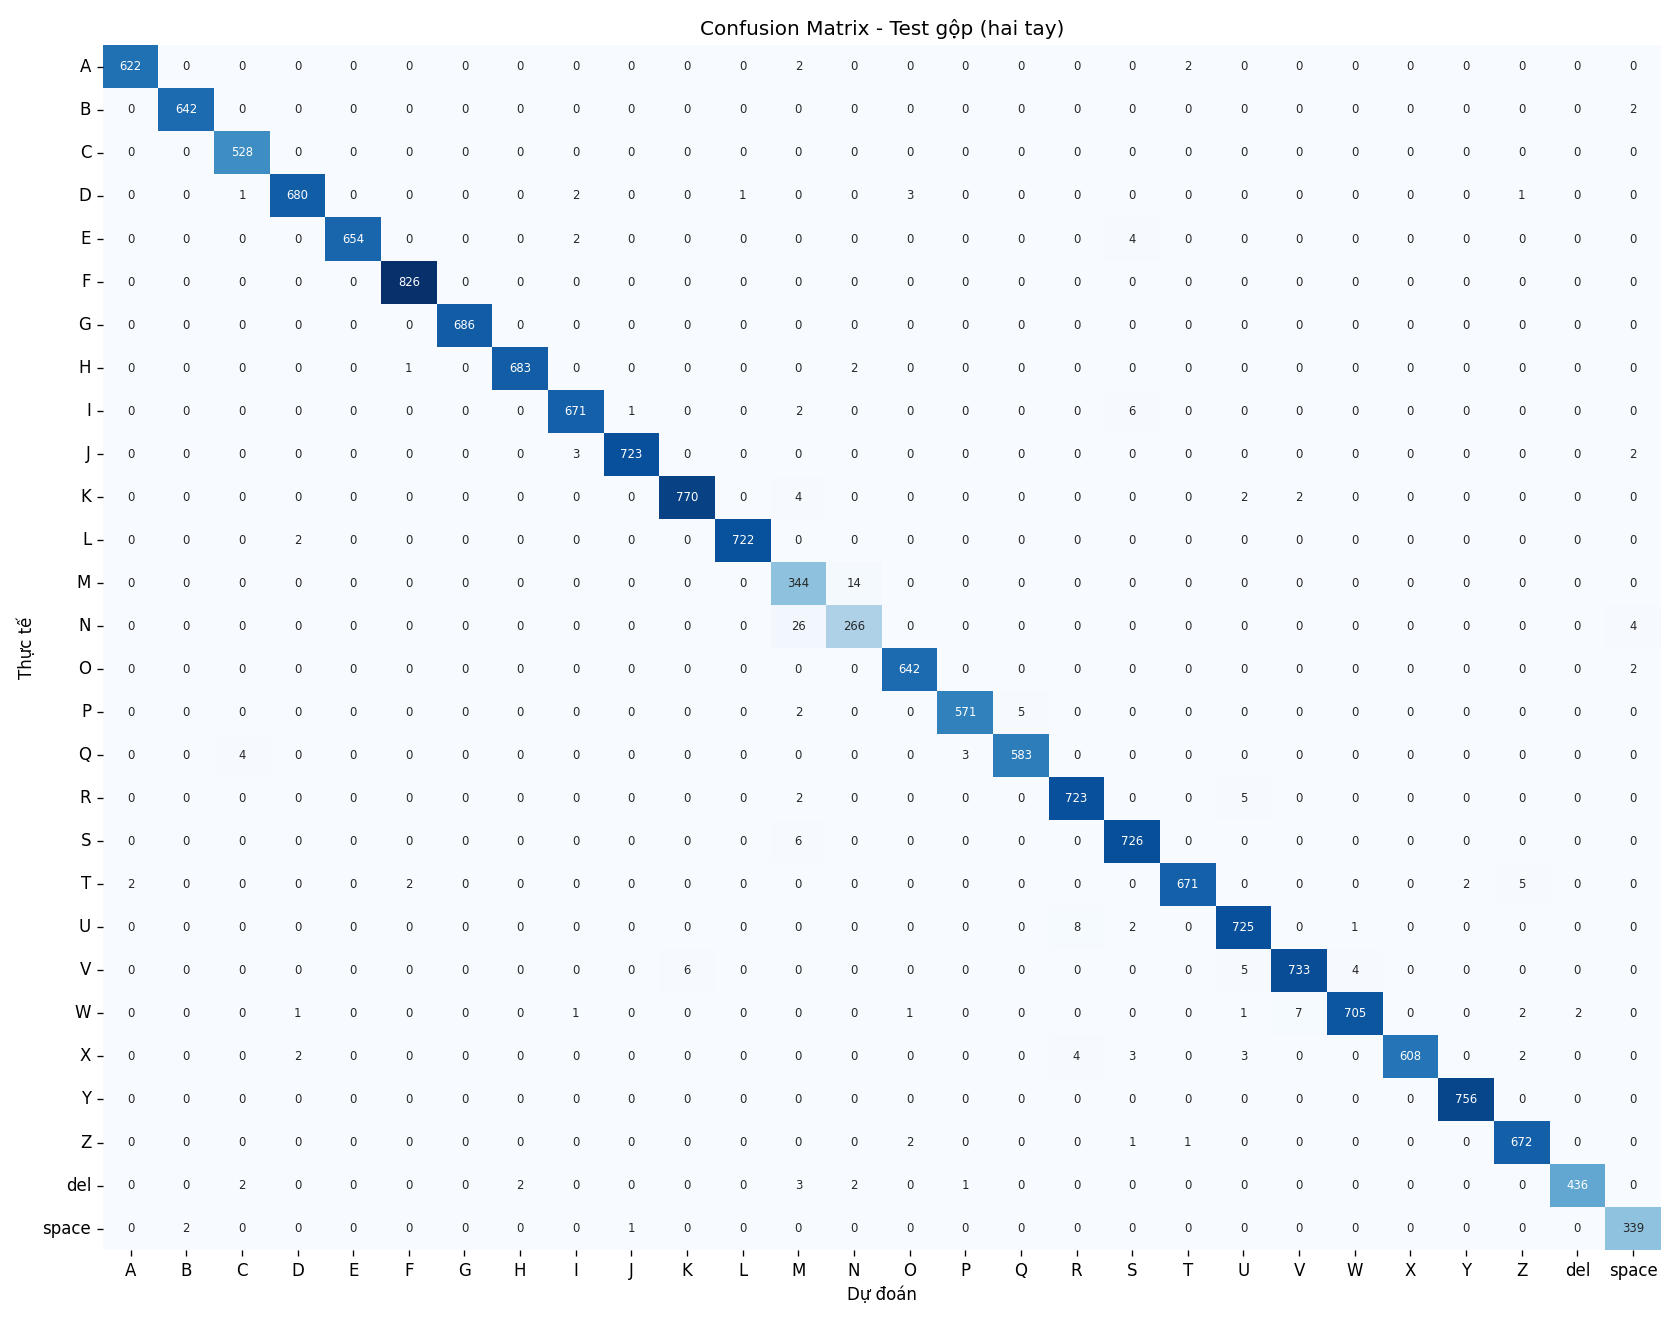

In [11]:
!python -m src.models.model1_mlp.evaluate

from IPython.display import Image, display
display(Image("reports/figures/model1_mlp_training_curves.png")) if os.path.exists("reports/figures/model1_mlp_training_curves.png") else None
display(Image("reports/confusion_matrices/model1_mlp_confusion_matrix.png"))

## Cell 5 — Demo webcam realtime
Bấm **Allow** khi trình duyệt hỏi quyền camera. Mô hình đã hỗ trợ nhận diện cả hai tay (tay trái lẫn tay phải) nhờ kỹ thuật data augmentation, lòng bàn tay hướng về camera.
Mặc định chạy trực tiếp mà không cần bật lật gương (`mirror=False`).

In [12]:
from src.demo.demo_webcam_model1 import run_webcam_demo
run_webcam_demo()

✅ Đã nạp Model 1. Các lớp: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'space']


<IPython.core.display.Javascript object>

📷 Camera đã bật: 640x480 - bấm nút ⏹ trên video để dừng.
Đã dừng. Tổng 5 khung hình, ~0.5 FPS.


KeyboardInterrupt: 

## Cell 6 — Tải model mới về máy tính
Chạy cell này để tải checkpoint `model1_mlp_best.pth` mới đã học dữ liệu cả 5 thành viên về máy tính.


In [ ]:
from google.colab import files
import os

print("📥 Đang chuẩn bị tải checkpoint và báo cáo về máy...")
if os.path.exists('checkpoints/model1_mlp_best.pth'):
    files.download('checkpoints/model1_mlp_best.pth')
if os.path.exists('reports/figures/model1_mlp_training_curves.png'):
    files.download('reports/figures/model1_mlp_training_curves.png')
if os.path.exists('reports/confusion_matrices/model1_mlp_confusion_matrix.png'):
    files.download('reports/confusion_matrices/model1_mlp_confusion_matrix.png')
